# FLAMINGO target and PKDGRAV IA model

Load the resolved FLAMINGO galaxies as the target sample, then populate the
PKDGRAV FoF halo lightcone with the portable central/satellite IA model. The
target weighted counts define both the total abundance and the frozen n(z).

In [1]:
%matplotlib inline
from pathlib import Path
import LSS_forward_model
import glass
import h5py
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq


from LSS_forward_model.cosmology import (make_shells_info_from_edges, read_sims_params, recover_shell_info)
from LSS_forward_model.halo_ia import (build_IA_halo_sources_from_catalog, build_halo_ia_maps, pixelize_shapes, project_inertia_tensor)
from LSS_forward_model.halos import save_halocatalog
from LSS_forward_model.PKDGRAV_and_postprocessing_utilities import build_z_values_file
from LSS_forward_model.maps import (build_shells,compute_lensing_fields,load_and_baryonify_gower_st_shells)


# Tensor decoding, projection, compact ellipticity I/O, and parallel
# transport are imported from their production modules above. Only the
# notebook-specific map and summary-statistic helpers remain here.

def read_objects(filename, columns):
    table = pq.read_table(filename, columns=columns)
    return {name: table[name].to_numpy() for name in columns}

# Spin-map routines

def spin_alms(value, lmax):
    return tuple(hp.map2alm_spin(
        [value.real.astype(float), value.imag.astype(float)], 2, lmax=lmax))


# Summary-statistic routines

def bin_cl(cl, bands):
    ell = np.arange(len(cl))
    centres, values = [], []
    for lower, upper in bands:
        use = (ell >= lower) & (ell < upper)
        modes = 2*ell[use]+1
        centres.append(np.sum(modes*ell[use])/np.sum(modes))
        values.append(np.sum(modes*cl[use])/np.sum(modes))
    return np.asarray(centres), np.asarray(values)

# IA model parameters

In [2]:
model_parameters = {
    'flamingo': {
        'ia': {'A_c': .798, 'eta_c': -.149, 'b_c': .00195,
               'A_s': .0965, 'eta_s': 2.44, 'b_s': .0526},
        'population': {'f_c': 1., 'f_sat': .103, 'sigma_logM': .2, 'alpha': 1.},
    },
    'pkdgrav': {
        'ia': {'A_c': .485, 'eta_c': -.151, 'b_c': .0508,
               'A_s': .258, 'eta_s': 1.40, 'b_s': -.0132},
        'population': {'f_c': .5, 'f_sat': .05, 'sigma_logM': .2, 'alpha': 1.},
    },
}

# note: we need a n(z) and total nuber count.

#-----------
seed = 913603
nside = 1024
lmax = nside*2

# FLAMINGO target inputs

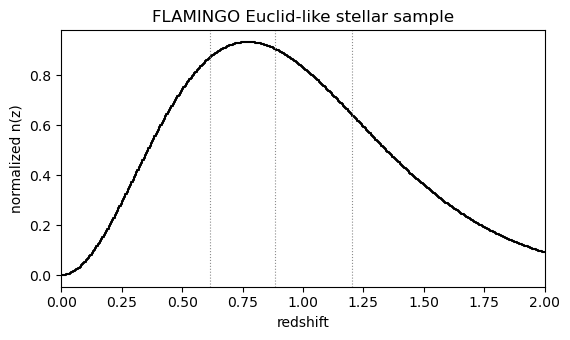

In [3]:
outputs = '/pscratch/sd/m/mgatti/IA_non_gaussian/outputs'
flamingo_root = Path('/global/cfs/cdirs/m5099/Flamingo/L1000N3600/L1_m8')
stars_file = flamingo_root/'IA_galaxies_all_resolved_z0p0_2p0_lc0.parquet'
# Per-snapshot host catalogue containing host_dm_inertia_tensor; documented
# here for provenance, but not loaded by this notebook.
flamingo_ia_halo_catalog = flamingo_root/'IA_hosts_z0p0_2p0'

'''
# This optional check shows how the stored FLAMINGO tensors were projected.
# stellar_inertia_tensor is ordered as (xx, yy, zz, xy, xz, yz).

columns = ['ra_deg', 'dec_deg', 'stellar_inertia_tensor', 'e1_IA', 'e2_IA']
flamingo = pq.ParquetFile(stars_file).read_row_group(0, columns=columns).slice(0, 200000)
flamingo_tensor = flamingo['stellar_inertia_tensor'].combine_chunks().values.to_numpy().reshape(-1, 6)
flamingo_ellipticity, _ = project_inertia_tensor(
    flamingo['ra_deg'].to_numpy(), flamingo['dec_deg'].to_numpy(), flamingo_tensor)

stored = flamingo['e1_IA'].to_numpy() + 1j*flamingo['e2_IA'].to_numpy()
np.testing.assert_allclose(flamingo_ellipticity, stored, rtol=2e-4, atol=2e-4)

'''

# Target n(z) -------------------------------------------------------------------
nz_file = outputs+'/z2_extension_20260910/sc_calibration/flamingo_tomographic_nz.npz'

nz = np.load(nz_file)

nz_edges = nz['nz_edges']
z_mid = 0.5 * (nz_edges[1:] + nz_edges[:-1])
delta_z = np.diff(nz_edges)

# Rows 8:12 are the four Euclid-like tomographic bins.
target_weighted_counts = nz['zhist'][8:12].sum(axis=0)

# Freeze the target abundance and redshift density used by the HOD.
total_number_counts = target_weighted_counts.sum()
target_nz = target_weighted_counts/total_number_counts
nz_redshift = z_mid
nz_values = target_weighted_counts/delta_z


fig, ax = plt.subplots(figsize=(5.8, 3.5))
ax.step(z_mid, target_nz/delta_z, where='mid', color='black')
for edge in nz['tomo_edges_by_sample'][2, 1:-1]:
    ax.axvline(edge, color='.55', ls=':', lw=.8)
ax.set(xlabel='redshift', ylabel='normalized n(z)', xlim=(0, 2),
       title='FLAMINGO Euclid-like stellar sample')
fig.tight_layout()


# Make the target e1/e2 map with the original calibration weights. -----------
columns = ['ra_deg', 'dec_deg', 'redshift', 'e1_IA', 'e2_IA']
target_objects = read_objects(stars_file, columns)
weight_bin = np.clip(np.searchsorted(nz['nz_edges'], target_objects['redshift'], side='right')-1, 0, len(nz['euclid_bin_weights'])-1)
target_weights = nz['euclid_bin_weights'][weight_bin]
target_marks = target_objects['e1_IA']+1j*target_objects['e2_IA']
target_pixelization = pixelize_shapes(target_objects['ra_deg'], target_objects['dec_deg'], target_marks, target_weights, nside)
target_map = target_pixelization['mean'].astype(np.complex64)





# PKDGRAV IA model

Build the compact FoF halo lightcone if it is absent, then populate it. The
population routine derives its redshift intervals from `shells_info` and stops
at the smaller of the halo-catalogue limit and the last non-zero n(z) point.

In [4]:
path_simulation = Path('/global/cfs/cdirs/m5099/GowerSt2/Flamingo_big')
project_path = Path(LSS_forward_model.__file__).resolve().parent.parent
pkdgrav_lightcone_path_baryons = path_simulation/'halo_catalog.parquet'
pkdgrav_lightcone_path_IA = path_simulation/'halo_catalog_ia_z2_m11p5.parquet'



 
# Cosmology and shell geometry -----------------------------------------------
sims_parameters, cosmo_bundle = read_sims_params(str(path_simulation))
z_values_path = path_simulation/'z_values.txt'
if not z_values_path.exists():
    build_z_values_file(str(path_simulation), 'run', out_dir=str(path_simulation),
                        sims_parameters=sims_parameters)
shells_info = recover_shell_info(str(z_values_path), max_z=sims_parameters['max_z'])
shells, steps, zeff_array = build_shells(shells_info)


# load density/shear shells --------------------------------
baryons = {
 "enabled": True,
 "max_z_halo_catalog": 0.5,
 "mass_cut": 12.5,
 "do_tSZ": False,
 "base_params_path": str(project_path/'Data/Baryonification_default_parameters.npy'),
 "filename_new_params": "sys_baryo_0.npy",
 "values_to_update":  None, # or: {'Mc': 10**13,'theta_ej' : 4.} or draw_params_from_specs( {"M_c": (12.5, 15.5, "log10"),   "theta_ej": (3.0, 10.0, "lin"),    "eta": (-2.0, -0.1, "log10")} )
}
density_prefix = 'delta_b' if baryons['enabled'] else 'delta'
dens_path = path_simulation/f'{density_prefix}_{nside}.npy'
tsz_path = path_simulation/f'tsz_{nside}.npy'


density, label_baryonification = load_and_baryonify_gower_st_shells(
  str(path_simulation),
  sims_parameters,
  cosmo_bundle,
  baryons,
  nside,
  shells_info,
  shells,
  overwrite_baryonified_shells=False,
  dens_path=str(dens_path),
  tsz_path=str(tsz_path),
  halo_catalog_path  = pkdgrav_lightcone_path_baryons
)

# PKDGRAV density is used only by the local IA response below.
# IA model  -------------------------------------------------
if not pkdgrav_lightcone_path_IA.exists():  # IA need a broader halo catalog...
    save_halocatalog(
        shells_info, sims_parameters, max_redshift=2.0,
        halo_snapshots_path=str(path_simulation)+'/', catalog_path=str(pkdgrav_lightcone_path_IA),
        log10_mass_limit=11.5)

model_objects = build_IA_halo_sources_from_catalog(
  path_halo_cat=str(pkdgrav_lightcone_path_IA),
  sims_parameters=sims_parameters,
  halo_catalog_log10mass_cut=11.5,
  total_number_counts=total_number_counts,
  nz_redshift=nz_redshift,
  nz=nz_values,
  shells_info=shells_info,
  model_parameters=model_parameters['pkdgrav'],
  cosmo_bundle=cosmo_bundle,
  seed=seed,
  quarter_turns=0,
)


ia_model = build_halo_ia_maps(model_objects, density, model_parameters['pkdgrav'], nside)
ia_maps = ia_model['maps']
ia_alms = {name: spin_alms(value, lmax) for name, value in ia_maps.items()}
print ('done')

100.0% | [##########] | Progress: 77 / 77 | Time: 2.5s | ETA: --               done


In [ ]:
# FLAMINGO and PKDGRAV density/shear x IA comparison -----------------------

def build_external_fields(density_shells, radial_windows, weights):
    """Build native tomographic density and lensing-shear maps."""
    fields = compute_lensing_fields(
        density_shells, radial_windows, cosmo_bundle['pars_camb'], nside,
        do_kappa=False, do_shear=True, do_IA=False)
    density_tomo = np.zeros((4, hp.nside2npix(nside)), np.float32)
    shear_tomo = np.zeros((4, hp.nside2npix(nside)), np.complex64)
    for shell in range(len(density_shells)):
        for tomo in range(4):
            density_tomo[tomo] += weights[tomo, shell]*density_shells[shell]
            shear_tomo[tomo] -= weights[tomo, shell]*fields['gamma'][shell, 0]

    maps, alms = {}, {}
    for tomo in range(4):
        d_alm = hp.map2alm(density_tomo[tomo], lmax=lmax, iter=0)
        g_alm = spin_alms(shear_tomo[tomo], lmax)[0]
        for prefix, alm in (('d', d_alm), ('G', g_alm)):
            value = hp.alm2map(alm, nside, lmax=lmax).astype(np.float32)
            value -= value.mean()
            maps[f'{prefix}{tomo}'] = value
            alms[f'{prefix}{tomo}'] = alm
    fields['density'] = density_shells
    return fields, density_tomo, shear_tomo, maps, alms


# Original FLAMINGO fields: the stored shell weights already match 41 planes.
flamingo_shell_file = flamingo_root/'overdensity_nside1024_lc0.hdf5'
flamingo_shell_weights = nz['shell_partitions'][8:12]
n_flamingo_shells = flamingo_shell_weights.shape[1]
flamingo_density = np.empty(
    (n_flamingo_shells, hp.nside2npix(nside)), np.float32)
flamingo_distance_edges = np.empty(n_flamingo_shells + 1)
with h5py.File(flamingo_shell_file) as source:
    keys = sorted(source)[:n_flamingo_shells]
    for index, key in enumerate(keys):
        plane = source[key]
        flamingo_density[index] = plane['overdensity'][:]
        flamingo_distance_edges[index] = plane.attrs['comoving_inner_radius']
        flamingo_distance_edges[index + 1] = plane.attrs['comoving_outer_radius']

z_grid = np.linspace(0, 2.2, 22001)
distance_grid = cosmo_bundle['cosmo_astropy'].comoving_distance(z_grid).value
flamingo_redshift_edges = np.interp(
    flamingo_distance_edges, distance_grid, z_grid)
flamingo_shells_info = make_shells_info_from_edges(
    flamingo_redshift_edges, flamingo_distance_edges)
flamingo_shells, _, _ = build_shells(flamingo_shells_info)
(flamingo_fields, flamingo_density_tomo, flamingo_shear_tomo,
 flamingo_external_maps, flamingo_external_alms) = build_external_fields(
    flamingo_density, flamingo_shells, flamingo_shell_weights)


# PKDGRAV has a different shell grid, so repartition the same frozen n(z).
pkdgrav_shell_weights = np.asarray([
    glass.shells.partition(z_mid, histogram/delta_z, shells)
    for histogram in nz['zhist'][8:12]])
pkdgrav_shell_weights /= pkdgrav_shell_weights.sum(axis=1, keepdims=True)
(pkdgrav_fields, pkdgrav_density_tomo, pkdgrav_shear_tomo,
 pkdgrav_external_maps, pkdgrav_external_alms) = build_external_fields(
    density, shells, pkdgrav_shell_weights)


# Cross each simulation's fields with its own IA realization.
target_alms = spin_alms(target_map, lmax)
cross_cls = {'flamingo': {}, 'pkdgrav': {}}
for statistic, prefix in (('GI', 'G'), ('dI', 'd')):
    cross_cls['flamingo'][statistic] = np.asarray([
        hp.alm2cl(flamingo_external_alms[f'{prefix}{tomo}'], target_alms[0])
        for tomo in range(4)])
    cross_cls['pkdgrav'][statistic] = np.asarray([
        hp.alm2cl(pkdgrav_external_alms[f'{prefix}{tomo}'], ia_alms['total'][0])
        for tomo in range(4)])



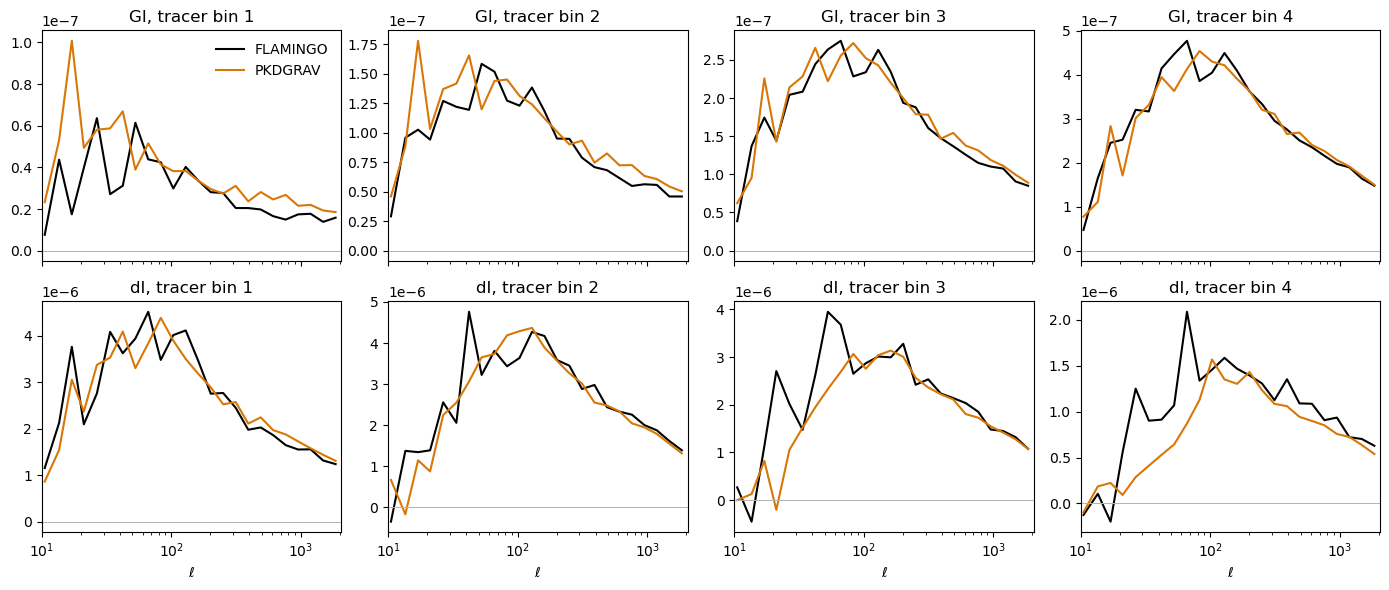

In [6]:
# Log-spaced bandpowers for the compact 4 x 2 comparison.
band_edges = np.unique(np.rint(np.geomspace(10, lmax + 1, 25)).astype(int))
comparison_bands = np.column_stack((band_edges[:-1], band_edges[1:]))
ell = bin_cl(np.zeros(lmax + 1), comparison_bands)[0]
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for row, statistic in enumerate(('GI', 'dI')):
    for tomo in range(4):
        ax = axes[row, tomo]
        for simulation, colour in (('flamingo', 'black'), ('pkdgrav', '#d97706')):
            bandpower = bin_cl(
                cross_cls[simulation][statistic][tomo], comparison_bands)[1]
            ax.plot(ell, bandpower*ell, color=colour, label=simulation.upper())
        ax.axhline(0, color='.7', lw=.7)
        ax.set(xscale='log', xlim=(10, lmax),
               title=f'{statistic}, tracer bin {tomo + 1}')
        if row == 1:
            ax.set_xlabel(r'$\ell$')
axes[0, 0].legend(frameon=False)
fig.tight_layout()
